## Steps1: Importing necessary Libraries

In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder

## Step2: Loading the Dataset

In [22]:
data = pd.read_csv("Data/demographics.csv")
data.head()

,first_name,last_name,blood_type,marriage_status,income,device
0,Abdul,Colon,A+,married,145000,AndroidOS
1,Abdul,Pierce,B+,married,85000,MacOS
2,Desirae,Pierce,B+,MARRIED,130000,iOS
3,Shannon,Gibson,A+,married,175000,MacOS
4,Desirae,Little,B+,unmarried,130000,MacOS


## Step3: Indentifying and Removing Bogus Blood Types

In [23]:
valid_blood_type_list = ['A+','A-','B+','B-','AB+','AB-','O+','O-'] ## Create a DataFrame
blood_type_categories = pd.DataFrame({'blood_type':valid_blood_type_list})
print(blood_type_categories)

  blood_type
0         A+
1         A-
2         B+
3         B-
4        AB+
5        AB-
6         O+
7         O-


In [24]:
unique_blood_types_main = set(data['blood_type'])
valid_blood_type_set = set(blood_type_categories['blood_type'])
bogus_blood_type = unique_blood_types_main.difference(valid_blood_type_set)
bogus_blood_type

{'C+', 'D-'}

In [25]:
bogus_records_index = data['blood_type'].isin(bogus_blood_type)
without_bogus_records = data[~bogus_records_index].copy()
without_bogus_records['blood_type'].unique()

array(['A+', 'B+', 'A-', 'AB-', 'AB+', 'B-', 'O-', 'O+'], dtype=object)

## Step4: Handling Inconsistent Marriage Status Categories

In [26]:
data['marriage_status'].unique()

array(['married', 'MARRIED', ' married', 'unmarried ', 'divorced',
       'unmarried', 'UNMARRIED', 'separated'], dtype=object)

In [27]:
inconsistent_data = data.copy()
inconsistent_data['marriage_status'] = inconsistent_data['marriage_status'].str.lower()
inconsistent_data['marriage_status'].unique()

array(['married', ' married', 'unmarried ', 'divorced', 'unmarried',
       'separated'], dtype=object)

In [28]:
inconsistent_data['marriage_status'] = inconsistent_data['marriage_status'].str.strip()
inconsistent_data['marriage_status'].unique()

array(['married', 'unmarried', 'divorced', 'separated'], dtype=object)

## Step5: Grouping Income into Meaningful Bins

In [29]:
print(f"Max income-{data['income'].max()}, Min income-{data['income'].min()}")

Max income-190000, Min income-40000


In [30]:
income_bins = [40000, 75000, 100000, 125000, 150000, np.inf]
income_labels = ['40k-75k','75k-100k','100k-125k','125k-150k','150k+']
remapping_data = data.copy()
remapping_data['income_groups'] = pd.cut(remapping_data['income'],
                                           bins = income_bins,
                                           labels = income_labels)
remapping_data.head()

,first_name,last_name,blood_type,marriage_status,income,device,income_groups
0,Abdul,Colon,A+,married,145000,AndroidOS,125k-150k
1,Abdul,Pierce,B+,married,85000,MacOS,75k-100k
2,Desirae,Pierce,B+,MARRIED,130000,iOS,125k-150k
3,Shannon,Gibson,A+,married,175000,MacOS,150k+
4,Desirae,Little,B+,unmarried,130000,MacOS,125k-150k


## Visualizing Income Group Distribution

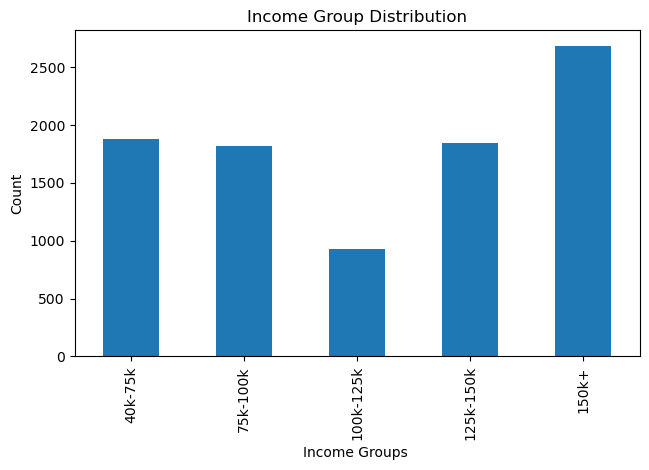

In [31]:
remapping_data['income_groups'].value_counts(). sort_index().plot.bar()
plt.title('Income Group Distribution')
plt.xlabel('Income Groups ')
plt.tight_layout()
plt.ylabel('Count')
plt.show()

## Step7: Cleaning Phone Number Data

In [36]:
import random 
phone_numbers = []

for i in range(1000):
    number = random.randint(100000000, 9999999999)
    if(i%2 == 0):
        phone_numbers.append('+91 '+str(number))
    else:
        phone_numbers.append(str(number))

phone_numbers_data = pd.DataFrame({'Phone_numbers':phone_numbers})
phone_numbers_data.head()

,Phone_numbers
0,+91 9895552164
1,6434194486
2,+91 1646829698
3,8356832048
4,+91 4010670595


In [39]:
phone_numbers_data['Phone_numbers'] = phone_numbers_data['Phone_numbers'].str.replace(r'\+91', '',regex=True)
num_digit = phone_numbers_data['Phone_numbers'].str.len()
invalid_numbers_index = phone_numbers_data[num_digit < 10].index 
phone_numbers_data.drop(invalid_numbers_index, inplace=True)

phone_numbers_data.dropna(inplace = True)
phone_numbers_data.reset_index(drop= True, inplace = True)
phone_numbers_data.head()

,Phone_numbers
0,9895552164
1,6434194486
2,1646829698
3,8356832048
4,4010670595


In [41]:
assert not phone_numbers_data['Phone_numbers'].str.contains(r'\+91 ').any(), "Found phone numbers with '+91 ' prefix"
assert (phone_numbers_data['Phone_numbers'].str.len() == 10).all(), "Some phone numbers do not have 10 digits"

AssertionError: Some phone numbers do not have 10 digits

## Step 8: Visualizing Categorical Data

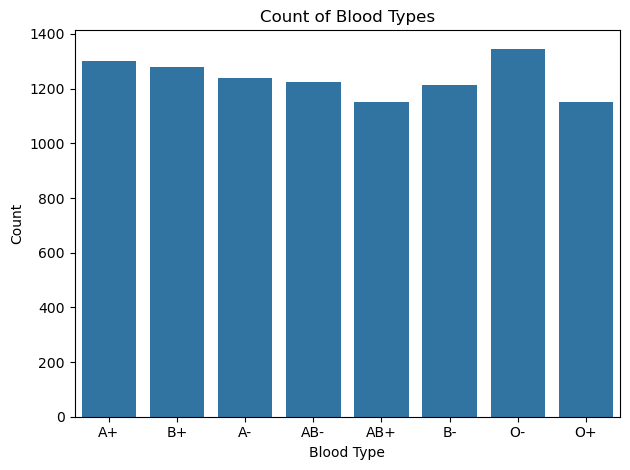

In [42]:
import seaborn as sns
sns.countplot(x='blood_type', data=without_bogus_records)
plt.title('Count of Blood Types')
plt.xlabel('Blood Type')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

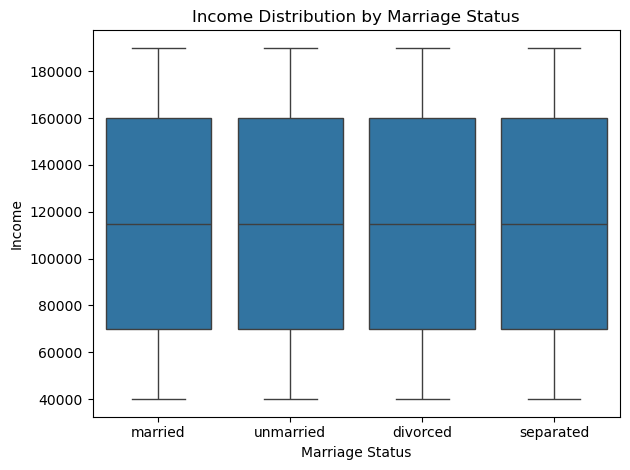

In [43]:
sns.boxplot(x='marriage_status', y='income', data=inconsistent_data)
plt.title('Income Distribution by Marriage Status')
plt.xlabel('Marriage Status')
plt.ylabel('Income') 
plt.tight_layout()
plt.show()

## Step 9: Encoding Categorical Data

In [46]:
le = LabelEncoder()
without_bogus_records['blood_type_encoded'] = le.fit_transform(without_bogus_records['blood_type'])
without_bogus_records[['blood_type', 'blood_type_encoded']].drop_duplicates()

,blood_type,blood_type_encoded
0,A+,0
1,B+,4
5,A-,1
7,AB-,3
9,AB+,2
10,B-,5
12,O-,7
21,O+,6


In [44]:
inconsistent_data = pd.get_dummies(inconsistent_data, columns=['marriage_status'])
inconsistent_data.head()

,first_name,last_name,blood_type,income,device,marriage_status_divorced,marriage_status_married,marriage_status_separated,marriage_status_unmarried
0,Abdul,Colon,A+,145000,AndroidOS,False,True,False,False
1,Abdul,Pierce,B+,85000,MacOS,False,True,False,False
2,Desirae,Pierce,B+,130000,iOS,False,True,False,False
3,Shannon,Gibson,A+,175000,MacOS,False,True,False,False
4,Desirae,Little,B+,130000,MacOS,False,False,False,True


In [47]:
custom_map = {
    '40k-75k': 1,
    '75k-100k': 2,
    '100k-125k': 3,
    '125k-150k': 4,
    '150k+': 5
}

remapping_data['income_groups_encoded'] = remapping_data['income_groups'].map(custom_map)

remapping_data[['income', 'income_groups', 'income_groups_encoded']].head()

,income,income_groups,income_groups_encoded
0,145000,125k-150k,4
1,85000,75k-100k,2
2,130000,125k-150k,4
3,175000,150k+,5
4,130000,125k-150k,4


**With these techniques we can prepare categorical data for meaningful analysis and effective machine learning models**